# Lab 5 - PCA on land-cover + autoencoder SR

Two parts:
1. Take patches from forest / urban / ocean and project them with PCA to 3D. Do the classes cluster?
2. Small autoencoder for super-resolution on an EO image. Does it really help?

I reuse Lab1 images (and a bit of Lab3 if needed). No huge downloads.

## Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from PIL import Image
from sklearn.decomposition import PCA
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("tf", tf.__version__)

tf 2.21.0


# Task 1 - PCA on land-cover patches

Idea: each patch is a high-dim RGB vector. PCA squeezes it to 3 numbers so we can plot it. If land-covers are different, they should form clusters in PC space.

forest (622, 800, 3) urban (800, 618, 3) ocean (629, 800, 3)


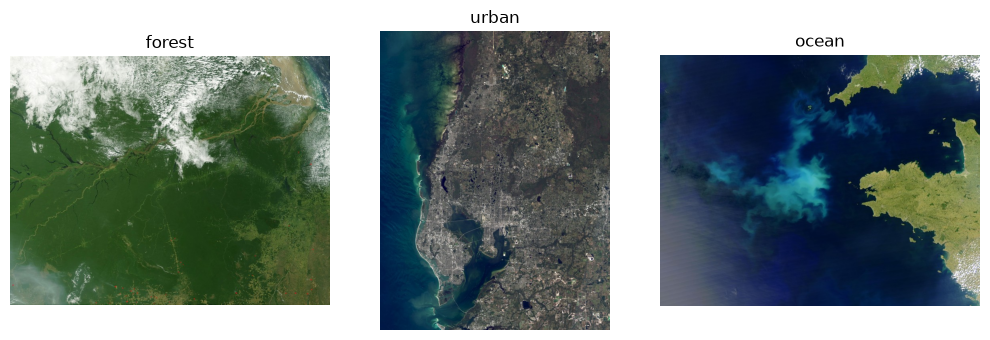

In [2]:
forest = np.asarray(Image.open("../Lab1/images/forest.jpg").convert("RGB"), dtype=np.float32) / 255.0
urban = np.asarray(Image.open("../Lab1/images/urban.jpg").convert("RGB"), dtype=np.float32) / 255.0
ocean = np.asarray(Image.open("../Lab1/images/ocean.jpg").convert("RGB"), dtype=np.float32) / 255.0

print("forest", forest.shape, "urban", urban.shape, "ocean", ocean.shape)

fig, ax = plt.subplots(1, 3, figsize=(10, 3.5))
ax[0].imshow(forest); ax[0].set_title("forest"); ax[0].axis("off")
ax[1].imshow(urban); ax[1].set_title("urban"); ax[1].axis("off")
ax[2].imshow(ocean); ax[2].set_title("ocean"); ax[2].axis("off")
plt.tight_layout()
plt.show()

Cut random 32x32 patches and flatten them. About 80 patches per class.

In [3]:
rng = np.random.default_rng(7)
PATCH = 32
N_PER = 80

def random_patches(img, n, size=PATCH):
    H, W, _ = img.shape
    out = []
    for _ in range(n):
        y = rng.integers(0, H - size + 1)
        x = rng.integers(0, W - size + 1)
        out.append(img[y:y+size, x:x+size].reshape(-1))
    return np.stack(out, axis=0)

X_f = random_patches(forest, N_PER)
X_u = random_patches(urban, N_PER)
X_o = random_patches(ocean, N_PER)

X = np.vstack([X_f, X_u, X_o])
y = np.array([0]*N_PER + [1]*N_PER + [2]*N_PER)
names = {0: "forest", 1: "urban", 2: "ocean"}
colors = {0: "green", 1: "red", 2: "blue"}

print("X shape", X.shape, "labels", y.shape)

X shape (240, 3072) labels (240,)


Fit PCA with 3 components and check explained variance.

In [4]:
pca = PCA(n_components=3, random_state=0)
Z = pca.fit_transform(X)
print("explained variance ratio:", pca.explained_variance_ratio_)
print("cumulative:", np.cumsum(pca.explained_variance_ratio_))

explained variance ratio: [0.6946833  0.0725151  0.04000302]
cumulative: [0.6946833  0.76719844 0.80720145]


2D and 3D scatter in PC space.

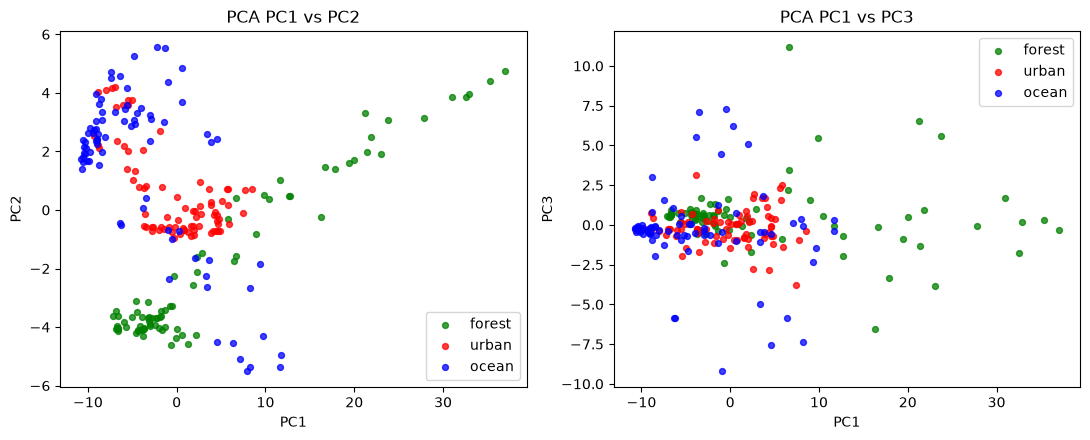

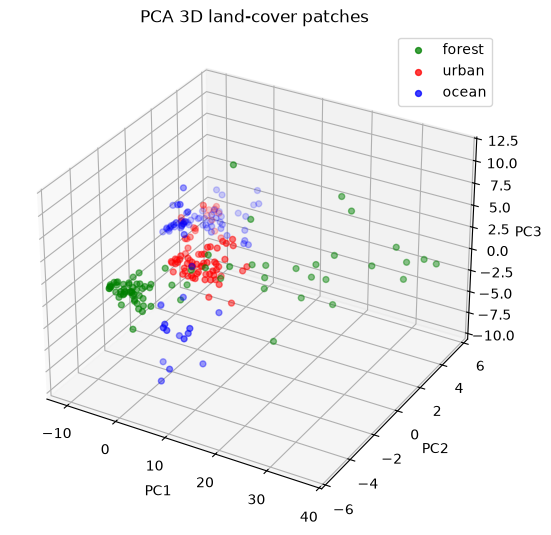

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))

for c in [0, 1, 2]:
    m = y == c
    ax[0].scatter(Z[m, 0], Z[m, 1], s=18, c=colors[c], label=names[c], alpha=0.75)
ax[0].set_xlabel("PC1")
ax[0].set_ylabel("PC2")
ax[0].set_title("PCA PC1 vs PC2")
ax[0].legend()

for c in [0, 1, 2]:
    m = y == c
    ax[1].scatter(Z[m, 0], Z[m, 2], s=18, c=colors[c], label=names[c], alpha=0.75)
ax[1].set_xlabel("PC1")
ax[1].set_ylabel("PC3")
ax[1].set_title("PCA PC1 vs PC3")
ax[1].legend()
plt.tight_layout()
plt.show()

fig = plt.figure(figsize=(7, 5.5))
ax3 = fig.add_subplot(111, projection="3d")
for c in [0, 1, 2]:
    m = y == c
    ax3.scatter(Z[m, 0], Z[m, 1], Z[m, 2], s=18, c=colors[c], label=names[c], alpha=0.75)
ax3.set_xlabel("PC1"); ax3.set_ylabel("PC2"); ax3.set_zlabel("PC3")
ax3.set_title("PCA 3D land-cover patches")
ax3.legend()
plt.tight_layout()
plt.show()

### Task 1 comment

The three land-covers do form pretty clear groups in PC space. Forest and ocean are usually easier to separate (green vs blue tones). Urban is more mixed / spread because cities have roofs, roads, shadows, sometimes trees. So PCA already shows that spectral/texture differences of these patches are strong enough to cluster without a fancy classifier.

# Task 2 - simple autoencoder for super-resolution

I take an EO image, cut HR patches, make LR by downsampling x2 and bicubic-upsampling back. Then a small conv autoencoder tries to map the blurry LR patch back toward HR.

This is a toy setup (synthetic degradation), so I do not expect magic results.

SR image (800, 618, 3)


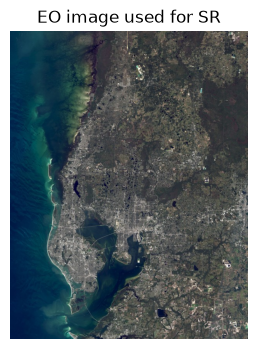

In [6]:
img = np.asarray(Image.open("../Lab1/images/urban.jpg").convert("RGB"), dtype=np.float32) / 255.0
print("SR image", img.shape)
plt.figure(figsize=(4, 4))
plt.imshow(img)
plt.title("EO image used for SR")
plt.axis("off")
plt.show()

In [7]:
HR_SIZE = 64
SCALE = 2
N_TRAIN = 200
N_TEST = 8

def make_pairs(image, n, size=HR_SIZE, scale=SCALE):
    H, W, _ = image.shape
    hr_list, lr_list = [], []
    for _ in range(n):
        y = rng.integers(0, H - size + 1)
        x = rng.integers(0, W - size + 1)
        hr = image[y:y+size, x:x+size]
        small = np.array(Image.fromarray((hr * 255).astype(np.uint8)).resize((size // scale, size // scale), Image.BICUBIC))
        lr_up = np.array(Image.fromarray(small).resize((size, size), Image.BICUBIC)).astype(np.float32) / 255.0
        hr_list.append(hr)
        lr_list.append(lr_up)
    return np.stack(hr_list), np.stack(lr_list)

hr_train, lr_train = make_pairs(img, N_TRAIN)
hr_test, lr_test = make_pairs(img, N_TEST)
print(hr_train.shape, lr_train.shape)

(200, 64, 64, 3) (200, 64, 64, 3)


Barebone conv autoencoder: compress, then upsample back. MSE loss.

In [8]:
keras.utils.set_random_seed(0)

model = keras.Sequential([
    layers.Input(shape=(HR_SIZE, HR_SIZE, 3)),
    layers.Conv2D(16, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),
    layers.Conv2D(32, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),
    layers.Conv2D(32, 3, activation="relu", padding="same"),
    layers.UpSampling2D(),
    layers.Conv2D(16, 3, activation="relu", padding="same"),
    layers.UpSampling2D(),
    layers.Conv2D(3, 3, activation="sigmoid", padding="same"),
])

model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 16)     │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 3)      │           435 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,395 (75.76 KB)

 Trainable params: 19,395 (75.76 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
hist = model.fit(lr_train, hr_train, epochs=15, batch_size=16, validation_split=0.15, verbose=1)

Epoch 1/15


 1/11 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - loss: 0.0702

 4/11 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0572

 7/11 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0470

10/11 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0423

11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 0.0412 - val_loss: 0.0254


... (80 outputs left out)

 4/11 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0047

 7/11 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0046

10/11 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0046

11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0046 - val_loss: 0.0046


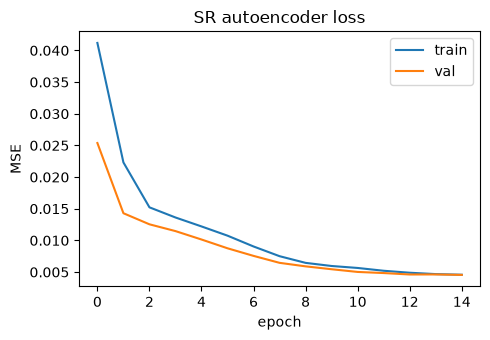

In [10]:
plt.figure(figsize=(5, 3.5))
plt.plot(hist.history["loss"], label="train")
plt.plot(hist.history["val_loss"], label="val")
plt.xlabel("epoch")
plt.ylabel("MSE")
plt.title("SR autoencoder loss")
plt.legend()
plt.tight_layout()
plt.show()

test MSE  bicubic-like LR: 0.001526
test MSE  autoencoder:     0.005105
test PSNR bicubic-like LR: 28.16 dB
test PSNR autoencoder:     22.92 dB


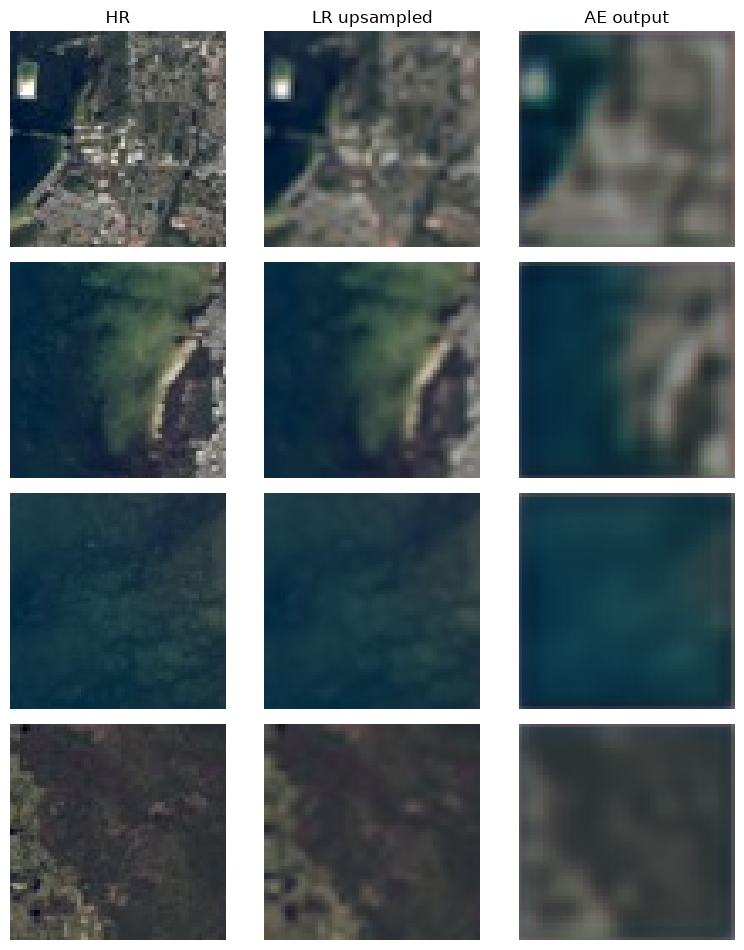

In [11]:
pred = model.predict(lr_test, verbose=0)

def psnr(a, b):
    mse = np.mean((a - b) ** 2)
    if mse < 1e-12:
        return 99.0
    return 10 * np.log10(1.0 / mse)

mse_bic = np.mean((lr_test - hr_test) ** 2)
mse_ae = np.mean((pred - hr_test) ** 2)
print(f"test MSE  bicubic-like LR: {mse_bic:.6f}")
print(f"test MSE  autoencoder:     {mse_ae:.6f}")
print(f"test PSNR bicubic-like LR: {psnr(lr_test, hr_test):.2f} dB")
print(f"test PSNR autoencoder:     {psnr(pred, hr_test):.2f} dB")

n_show = 4
fig, ax = plt.subplots(n_show, 3, figsize=(8, 2.4 * n_show))
for i in range(n_show):
    ax[i, 0].imshow(np.clip(hr_test[i], 0, 1)); ax[i, 0].set_ylabel(f"#{i}")
    ax[i, 1].imshow(np.clip(lr_test[i], 0, 1))
    ax[i, 2].imshow(np.clip(pred[i], 0, 1))
    for j in range(3):
        ax[i, j].axis("off")
ax[0, 0].set_title("HR")
ax[0, 1].set_title("LR upsampled")
ax[0, 2].set_title("AE output")
plt.tight_layout()
plt.show()

### Task 2 comment

Does it enhance resolution? On this run: **not really**. Bicubic LR upsample had better MSE/PSNR than the small AE. The AE output still looks soft and sometimes blurrier / washed out.

That is expected for a tiny model, few epochs, and fake downsample training from one urban photo. It mostly tries to map blur→sharp but does not recover real high-frequency satellite detail.

How to make it better:
- more EO images / more diverse patches (not only one urban photo)
- real LR-HR pairs instead of fake downsample
- deeper residual / U-Net style model
- more epochs + better loss (perceptual / SSIM), maybe residual learning
- train on many scenes, test on a held-out image


## Short wrap-up

- PCA: land-cover patches do cluster in 3 PC dimensions; urban is the noisiest class.
- AE-SR: the small Keras autoencoder did **not** beat bicubic here. Real super-resolution needs better data and a stronger model.
